# Paper 3 — Train β=1 and β=4 on dSprites
Run cells sequentially on Colab GPU (A100 or T4). No automatic dataset downloads. The two **long** training cells are separate and never run from setup. See README for scientific assumptions.

In [ ]:
# Clone private source without embedding or printing the access token.
from pathlib import Path
import os, subprocess, tempfile, stat
from google.colab import userdata

REPO = Path('/content/advanced-ml-paper-reproductions')
PROJECT = REPO / 'paper3-beta-vae'
if not PROJECT.exists():
    token = userdata.get('GITHUB_TOKEN')
    if not token:
        raise RuntimeError('Add GITHUB_TOKEN to Colab Secrets and grant notebook access.')
    with tempfile.TemporaryDirectory() as tmp:
        askpass = Path(tmp) / 'askpass.sh'
        askpass.write_text('#!/bin/sh\ncase "$1" in\n  *Username*) printf "x-access-token" ;;\n  *Password*) printf "%s" "$GITHUB_TOKEN" ;;\nesac\n')
        askpass.chmod(0o700)
        env = dict(os.environ, GITHUB_TOKEN=token, GIT_ASKPASS=str(askpass), GIT_TERMINAL_PROMPT='0')
        subprocess.run(['git','clone','--quiet', 'https://github.com/vepaan/advanced-ml-paper-reproductions.git',str(REPO)], env=env, check=True)
    del token
    print('Cloned private repository to', REPO)
else:
    print('Reusing existing project checkout:', PROJECT)
assert (PROJECT / 'src' / 'models.py').is_file(), 'Push paper3-beta-vae/ into GitHub first and rerun setup.'
%cd /content/advanced-ml-paper-reproductions/paper3-beta-vae
# Colab usually ships matplotlib. Install if missing; do NOT replace Colab torch with old Windows pins.
import importlib.util
if importlib.util.find_spec('matplotlib') is None:
    subprocess.run(['python','-m','pip','install','-q','matplotlib'],check=True)
import torch
print('torch:',torch.__version__,'CUDA:',torch.cuda.is_available(),
      'GPU:',torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'none')


Reusing existing project checkout: /content/advanced-ml-paper-reproductions/paper3-beta-vae
/content/advanced-ml-paper-reproductions/paper3-beta-vae
torch: 2.11.0+cu130 CUDA: True GPU: Tesla T4


In [ ]:

from pathlib import Path
from google.colab import userdata
import os
import subprocess
import tempfile

REPO = Path('/content/advanced-ml-paper-reproductions')

token = userdata.get('GITHUB_TOKEN')
assert token, "GITHUB_TOKEN missing from Colab Secrets"

with tempfile.TemporaryDirectory() as tmp:
    askpass = Path(tmp) / 'askpass.sh'
    askpass.write_text(
        '#!/bin/sh\n'
        'case "$1" in\n'
        '  *Username*) printf "x-access-token" ;;\n'
        '  *Password*) printf "%s" "$GITHUB_TOKEN" ;;\n'
        'esac\n'
    )
    askpass.chmod(0o700)

    env = dict(
        os.environ,
        GITHUB_TOKEN=token,
        GIT_ASKPASS=str(askpass),
        GIT_TERMINAL_PROMPT='0'
    )

    print("Current commit:")
    subprocess.run(
        ['git', 'log', '-1', '--oneline'],
        cwd=REPO, check=True
    )

    print("\nPulling latest changes...")
    subprocess.run(
        ['git', 'pull', '--ff-only'],
        cwd=REPO, env=env, check=True
    )

    print("\nUpdated commit:")
    subprocess.run(
        ['git', 'log', '-1', '--oneline'],
        cwd=REPO, check=True
    )

del token

print("\nGit pull complete.")


Current commit:

Pulling latest changes...

Updated commit:

Git pull complete.


In [ ]:
!git log --oneline

67c83ff (HEAD -> main, origin/main, origin/HEAD) minor nit
6147511 updated visualize
09f227a paper3 boilerplate
06412be PHASE 4 for paper2 done
10bc701 PHASE 4: author's code commited
8d10f15 Merge branch 'main' of https://github.com/vepaan/advanced-ml-paper-reproductions
84562a3 PHASE 3 figure reproduction done
35e4869 PHASE 3 figure reproduction done
3cc837b paper2: support checkpoint LR refinement
d9da2e4 paper2 boilerplate
ced4e6d PHASE 3 figure reproduction done
b76af2a results and small train change
f569e90 training checkpoint
6e2e3ba add indexed experiemnts and early stopping after convergence
a59dc3d small change
74ec31b requirements added
ef55eb1 experiment code written
77e2e23 update gitignore
c1cc9ae updated alexnet to match param count, inception still not match
bf27956 adding data
0d2f291 more boilerplate
57a3676 boilerplate
3198b5a boilerplate


In [ ]:

from google.colab import drive
from pathlib import Path

drive.mount('/content/drive')

FNAME = 'dsprites_ndarray_co1sh3sc6or40x32y32_64x64.npz'

# Load dataset directly from the cloned repository
PROJECT_DIR = Path('/content/advanced-ml-paper-reproductions/paper3-beta-vae')
DATA_DIR = PROJECT_DIR / 'data'
DATA = DATA_DIR / FNAME

if not DATA.is_file():
    raise FileNotFoundError(
        f'Dataset not found: {DATA}\n'
        'Make sure the repository was cloned and the .npz was committed.'
    )

assert DATA.stat().st_size > 1_000_000, (
    'Unexpectedly small NPZ. Check your committed dataset.'
)

# Training outputs: fast local storage + persistent Drive backup
LOCAL_RUNS = Path('/content/paper3_runs')
DRIVE_RUNS = Path('/content/drive/MyDrive/ML-Paper-Reproductions/paper3')

LOCAL_RUNS.mkdir(parents=True, exist_ok=True)
DRIVE_RUNS.mkdir(parents=True, exist_ok=True)

print('Dataset:', DATA)
print(f'Dataset size: {DATA.stat().st_size / 1024**2:.1f} MiB')
print('Local runs:', LOCAL_RUNS)
print('Drive backups:', DRIVE_RUNS)


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Dataset: /content/advanced-ml-paper-reproductions/paper3-beta-vae/data/dsprites_ndarray_co1sh3sc6or40x32y32_64x64.npz
Dataset size: 18.4 MiB
Local runs: /content/paper3_runs
Drive backups: /content/drive/MyDrive/ML-Paper-Reproductions/paper3


In [ ]:
%cd /content/advanced-ml-paper-reproductions/paper3-beta-vae

# Paper 3 — GPU validation and benchmark

import torch

assert torch.cuda.is_available(), "Select a GPU runtime."

print("GPU:", torch.cuda.get_device_name(0))
print("Dataset:", DATA)
print("Starting validation and benchmark...\n", flush=True)

!python -u -m src.validate \
    --paper-model \
    --data "{DATA}" \
    --benchmark \
    --device cuda \
    --batch-size 256 \
    --max-steps 12000 \
    --warmup 3 \
    --measured 12

print("\nBenchmark finished.")

/content/advanced-ml-paper-reproductions/paper3-beta-vae
GPU: Tesla T4
Dataset: /content/advanced-ml-paper-reproductions/paper3-beta-vae/data/dsprites_ndarray_co1sh3sc6or40x32y32_64x64.npz
Starting validation and benchmark...

{
  "status": "PASS",
  "hidden_dim": 1200,
  "parameters": 14196516,
  "input_shape": [
    2,
    4096
  ],
  "mu_shape": [
    2,
    10
  ],
  "beta4_loss": 2843.840576171875,
  "recon": 2843.712890625,
  "kl": 0.031919509172439575,
  "data_mapping_roundtrip": true
}
DATA PASS: official NPZ, shape, factor indexing, binary samples and memory-mapped cache
{
  "device": "cuda",
  "steps_measured": 12,
  "batch_size": 256,
  "sec_per_step": 0.0127,
  "samples_per_sec": 20184.7,
  "estimated_training_minutes_per_beta": 2.5,
  "estimated_both_training_minutes": 5.1,
  "estimated_full_dataset_eval_minutes_each": 0.1,
  "estimates_note": "Warm GPU benchmark extrapolation, NOT actual completed training time.",
  "max_gpu_allocated_mib": 296.1
}

Benchmark finished.


## Standard VAE (Figure 7B): β = 1
One seed (2026); initial weights and shuffled minibatches match β=4. Adagrad 0.01; look at real benchmark before running. This cell resumes from a saved checkpoint when rerun.

In [ ]:

import sys

MAX_STEPS = 30000
BATCH_SIZE = 256

!{sys.executable} -u -m src.train \
    --beta 1 \
    --data "{DATA}" \
    --output-root "{LOCAL_RUNS}" \
    --backup-root "{DRIVE_RUNS}" \
    --max-steps {MAX_STEPS} \
    --batch-size {BATCH_SIZE} \
    --learning-rate 0.01 \
    --seed 2026 \
    --ckpt-every 2000 \
    --log-every 500


RESUMED beta1 at step 12000 (epoch 4, next batch 480) from /content/paper3_runs/beta1/latest.pt
Parameters=14,196,516; samples=737,280; batch=256; requested_steps=30000; device=cuda
{"step": 12500, "epoch": 4.3403, "loss": 90.90335, "recon": 75.66516, "kl": 15.23821, "elapsed_sec": 4.5}
{"step": 13000, "epoch": 4.5139, "loss": 90.47653, "recon": 75.24244, "kl": 15.23407, "elapsed_sec": 8.6}
{"step": 13500, "epoch": 4.6875, "loss": 90.06487, "recon": 74.79688, "kl": 15.26795, "elapsed_sec": 12.8}
{"step": 14000, "epoch": 4.8611, "loss": 89.64467, "recon": 74.38542, "kl": 15.25934, "elapsed_sec": 16.9}
SAVED step=14000: /content/paper3_runs/beta1/latest.pt
{"step": 14500, "epoch": 5.0347, "loss": 89.28426, "recon": 74.01419, "kl": 15.27007, "elapsed_sec": 23.1}
{"step": 15000, "epoch": 5.2083, "loss": 88.90266, "recon": 73.63476, "kl": 15.26797, "elapsed_sec": 27.3}
{"step": 15500, "epoch": 5.3819, "loss": 88.91322, "recon": 73.61758, "kl": 15.29559, "elapsed_sec": 31.6}
{"step": 16000, 

## β-VAE (Figure 7A): β = 4
Identical initialization and batch order; only KL multiplier changes. One seed is insufficient to establish robustness.

In [ ]:

!{sys.executable} -u -m src.train \
    --beta 4 \
    --data "{DATA}" \
    --output-root "{LOCAL_RUNS}" \
    --backup-root "{DRIVE_RUNS}" \
    --max-steps {MAX_STEPS} \
    --batch-size {BATCH_SIZE} \
    --learning-rate 0.01 \
    --seed 2026 \
    --ckpt-every 2000 \
    --log-every 500


RESUMED beta4 at step 12000 (epoch 4, next batch 480) from /content/paper3_runs/beta4/latest.pt
Parameters=14,196,516; samples=737,280; batch=256; requested_steps=30000; device=cuda
{"step": 12500, "epoch": 4.3403, "loss": 135.11749, "recon": 95.38419, "kl": 9.93334, "elapsed_sec": 4.7}
{"step": 13000, "epoch": 4.5139, "loss": 134.98865, "recon": 95.23184, "kl": 9.93919, "elapsed_sec": 9.1}
{"step": 13500, "epoch": 4.6875, "loss": 134.86809, "recon": 95.1087, "kl": 9.93987, "elapsed_sec": 13.6}
{"step": 14000, "epoch": 4.8611, "loss": 134.94818, "recon": 95.19231, "kl": 9.93897, "elapsed_sec": 18.1}
SAVED step=14000: /content/paper3_runs/beta4/latest.pt
{"step": 14500, "epoch": 5.0347, "loss": 134.69879, "recon": 94.90981, "kl": 9.94724, "elapsed_sec": 24.6}
{"step": 15000, "epoch": 5.2083, "loss": 134.44362, "recon": 94.68843, "kl": 9.93879, "elapsed_sec": 29.2}
{"step": 15500, "epoch": 5.3819, "loss": 134.70142, "recon": 94.93299, "kl": 9.9421, "elapsed_sec": 33.8}
{"step": 16000, "e

In [ ]:
import torch
for beta in (1,4):
    local = LOCAL_RUNS / f'beta{beta}' / 'model.pt'
    assert local.exists(), f'Missing {local}'
    c=torch.load(local,map_location='cpu',weights_only=False)
    assert c['beta']==beta and c['step']>=MAX_STEPS
    print(f'β={beta} step={c["step"]} seed={c["seed"]} inference state={local}')
print('Next: run reproduce_figure7.ipynb (no training required).')


β=1 step=30000 seed=2026 inference state=/content/paper3_runs/beta1/model.pt
β=4 step=30000 seed=2026 inference state=/content/paper3_runs/beta4/model.pt
Next: run reproduce_figure7.ipynb (no training required).


generate figures now

In [ ]:

from pathlib import Path
import torch

PROJECT = Path('/content/advanced-ml-paper-reproductions/paper3-beta-vae')
FNAME = 'dsprites_ndarray_co1sh3sc6or40x32y32_64x64.npz'

DATA = PROJECT / 'data' / FNAME
RUNS = Path('/content/paper3_runs')
BACKUP = Path('/content/drive/MyDrive/ML-Paper-Reproductions/paper3')
FIGURES = Path('/content/paper3_figure7')

FIGURES.mkdir(parents=True, exist_ok=True)

assert DATA.is_file(), f'Missing dataset: {DATA}'

for beta in (1, 4):
    checkpoint = RUNS / f'beta{beta}' / 'model.pt'
    assert checkpoint.is_file(), f'Missing checkpoint: {checkpoint}'
    print(f'Beta {beta}: checkpoint found')

print('Dataset:', DATA)
print('Output:', FIGURES)
print('GPU:', torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'CPU')

%cd /content/advanced-ml-paper-reproductions/paper3-beta-vae


Beta 1: checkpoint found
Beta 4: checkpoint found
Dataset: /content/advanced-ml-paper-reproductions/paper3-beta-vae/data/dsprites_ndarray_co1sh3sc6or40x32y32_64x64.npz
Output: /content/paper3_figure7
GPU: Tesla T4
/content/advanced-ml-paper-reproductions/paper3-beta-vae


In [ ]:
import sys
from pathlib import Path

DATA = Path('/content/advanced-ml-paper-reproductions/paper3-beta-vae/data/dsprites_ndarray_co1sh3sc6or40x32y32_64x64.npz')
RUNS = Path('/content/paper3_runs')
FIGURES = Path('/content/paper3_figure7_corrected')

!{sys.executable} -u -m src.visualize --panel both --data "{DATA}" --output-root "{RUNS}" --figures-dir "{FIGURES}" --device auto --eval-batch-size 2048


Figure 7A ready {"step": 30000, "latents": [6, 5, 4, 10, 8, 7], "kl": [0.0004, 0.0006, 0.0012, 2.1688, 2.8496, 2.9325, 0.0004, 0.0004, 0.0006, 2.0165]}
Figure 7B ready {"step": 30000, "latents": [6, 8, 4, 3, 9, 1], "kl": [0.0103, 0.1113, 2.6798, 3.5377, 0.1591, 3.7477, 0.0464, 3.5463, 1.8469, 0.0108]}
Plot limits (same for BOTH beta arms): {"position_mean": 3.0637785403264894, "scale_mean": 1.4068034548805373, "rotation_mean": 2.0740510697626933}
Output: /content/paper3_figure7_corrected


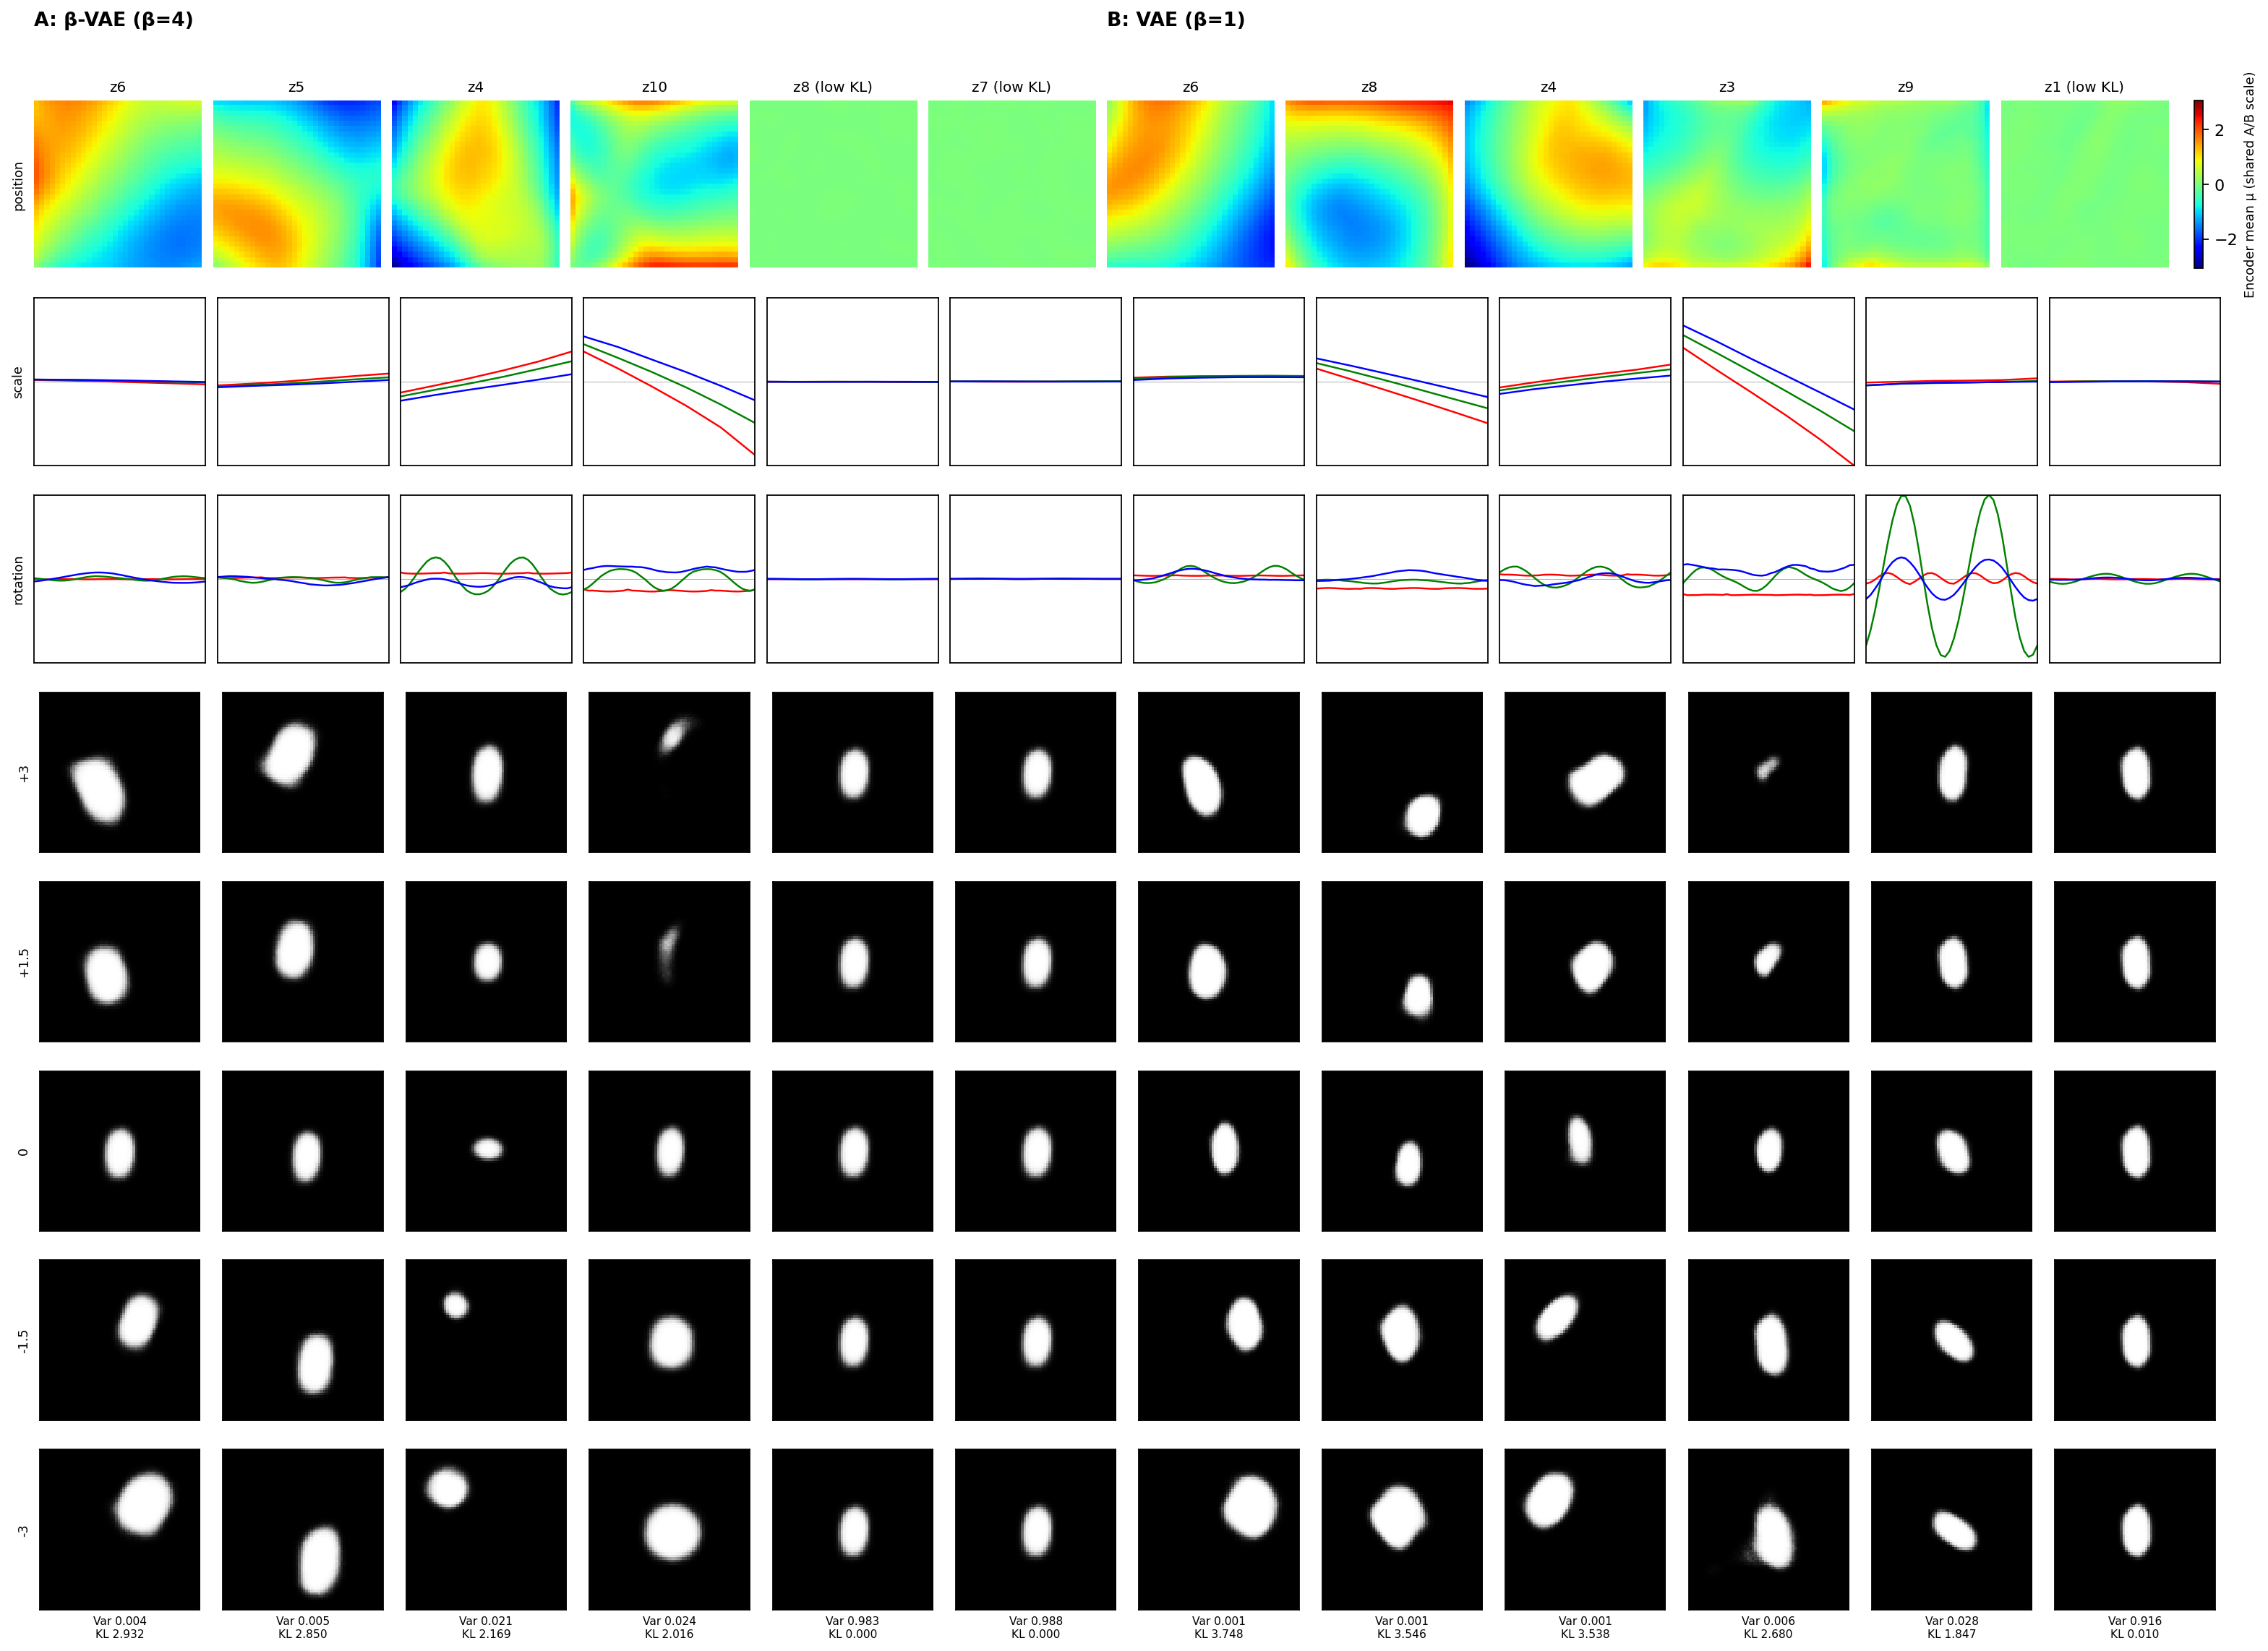


Figure 7A: beta=4.0, steps=30000
z6: KL=2.9325, signals={'position_x': 0.536, 'position_y': 0.46, 'scale': 0.0, 'rotation': 0.003}
z5: KL=2.8496, signals={'position_x': 0.475, 'position_y': 0.518, 'scale': 0.004, 'rotation': 0.003}
z4: KL=2.1688, signals={'position_x': 0.73, 'position_y': 0.156, 'scale': 0.057, 'rotation': 0.057}
z10: KL=2.0165, signals={'position_x': 0.036, 'position_y': 0.553, 'scale': 0.387, 'rotation': 0.023}
z8: KL=0.0004, signals={'position_x': 0.251, 'position_y': 0.255, 'scale': 0.195, 'rotation': 0.299}
z7: KL=0.0004, signals={'position_x': 0.235, 'position_y': 0.208, 'scale': 0.15, 'rotation': 0.407}

Figure 7B: beta=1.0, steps=30000
z6: KL=3.7477, signals={'position_x': 0.653, 'position_y': 0.337, 'scale': 0.0, 'rotation': 0.01}
z8: KL=3.5463, signals={'position_x': 0.213, 'position_y': 0.713, 'scale': 0.072, 'rotation': 0.003}
z4: KL=3.5377, signals={'position_x': 0.588, 'position_y': 0.383, 'scale': 0.014, 'rotation': 0.014}
z3: KL=2.6798, signals={'posit

In [ ]:

import json
from IPython.display import display, Image

display(Image(filename=str(FIGURES / 'figure7_AB.png')))

with open(FIGURES / 'figure7_metrics.json') as f:
    metrics = json.load(f)

for label in ('A', 'B'):
    m = metrics[label]
    fractions = m['factor_response_diagnostics']['within_4_factor_signal_fractions']

    print(f'\nFigure 7{label}: beta={m["beta"]}, steps={m["steps"]}')

    for latent_id in m['displayed_latent_ids_1_based']:
        j = latent_id - 1
        signals = {
            name: round(values[j], 3)
            for name, values in fractions.items()
        }
        print(f'z{latent_id}: KL={m["mean_kl_all_10"][j]:.4f}, signals={signals}')
